In [15]:
# Import libraries - numpy, pandas, matplotlib, seaborn, and scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split

# Make it so plots display in the notebook
%matplotlib inline

In [16]:
# Read and view the data - 2026 Lead-Scoring data. Same as HW3. Call it leads.
leads = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")
leads.tail()
# 5000 data points
# Target variable is converted - 1 if a lead signed up for the platform, and 0 if not

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1
4999,referral,technology,employed,europe,81355.0,6,11,0.99,1


In [17]:
# Data Preparation
# Check if the missing values are presented in the features.
# If there are missing values:
# For categorical features, replace them with 'NA'
# For numerical features, replace with with 0.0

# Now check for missing values
leads.isnull().sum()
# lead_source, industry, employment_status, location, annual_income, and lead_score all have missing values.

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [18]:
# Check the variables to determine if they are categorical or numeric
pd.DataFrame([leads.dtypes, leads.nunique()], index=["Data Type", "Unique Values"])

# From the results of this and the tail() examination earlier, can determine the following:
# categorical variables: lead_source, industry, employment_status, location
# numeric variables: annual_income, lead_score

# None of the categorical variables are binary, aside from the target.

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
Data Type,str,str,str,str,float64,int64,int64,float64,int64
Unique Values,5,6,4,5,4313,7,14,99,2


In [19]:
# Save these variables to lists based on whether they are categorical or numeric.
categorical_vars = ['lead_source', 'industry', 'employment_status', 'location']
numeric_vars = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


# For each categorical variable, replace missing values with 'NA' as instructed
leads[categorical_vars] = leads[categorical_vars].fillna('NA')

# For each numeric variable, replace missing values with 0.0 as instructed
leads[numeric_vars] = leads[numeric_vars].fillna(0.0)

In [20]:
# Split the data into three parts as instructed:
df_full_train, df_test = train_test_split(leads, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

# Extract X_train, y_train, X_val, y_val, X_full_train, y_full_train, X_test, and y_test
X_train = df_train.loc[:, df_train.columns != 'converted']
y_train = df_train.converted.values
X_val = df_val.loc[:, df_val.columns != 'converted']
y_val = df_val.converted.values
X_full_train = df_full_train.loc[:, df_full_train.columns != 'converted']
y_full_train = df_full_train.converted.values
X_test = df_test.loc[:, df_test.columns != 'converted']
y_test = df_test.converted.values

In [21]:
# Question 1: ROC AUC feature importance

# ROC AUC could also be used to evaluate feature importance of numerical variables. Let's do that.
# For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
# Use the training dataset for that.
# If your AUC is < 0.5, invert this variable by putting "-" in front (e.g. -df_train['balance'])
# AUC can go below 0.5 if the variable is negatively correlated with the target variable. 
# You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

# Which numerical variable (among the following 4) has the highest AUC?

#

In [22]:
# Question 2: Training the model
# Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:
# LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
# What's the AUC of this model on the validation dataset? (round to 3 digits)

# First need to one-hot encode the categorical variables. Use DictVectorizer
from sklearn.feature_extraction import DictVectorizer
dv = DictVectorizer(sparse=False)

# Prepare the data by converting to dictionaries
train_dict = X_train.to_dict(orient='records')
val_dict = X_val.to_dict(orient='records')

# Perform the one-hot encoding on X_train
X_train = dv.fit_transform(train_dict)
X_train = pd.DataFrame(X_train, columns=dv.get_feature_names_out())

# Examine X_train to make sure the one-hot encoding was successful
X_train.head().T
# Yes, it worked!

,0,1,2,3,4
annual_income,80198.00,50548.00,76300.00,80371.00,73567.00
employment_status=NA,0.00,0.00,0.00,0.00,0.00
employment_status=employed,1.00,1.00,1.00,1.00,1.00
employment_status=self_employed,0.00,0.00,0.00,0.00,0.00
employment_status=student,0.00,0.00,0.00,0.00,0.00
employment_status=unemployed,0.00,0.00,0.00,0.00,0.00
industry=NA,0.00,0.00,0.00,0.00,0.00
industry=education,0.00,0.00,0.00,0.00,0.00
industry=finance,0.00,0.00,1.00,1.00,1.00
industry=healthcare,0.00,0.00,0.00,0.00,0.00


In [23]:
# Question 2

# Do the one-hot encoding for X_val as well.
X_val = dv.fit_transform(val_dict)
X_val = pd.DataFrame(X_val, columns=dv.get_feature_names_out())

# Train the logistic regression as instructed
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

# Calculate the accuracy on the validation dataset and round it to 2 decimal digits.
y_pred_probs = model.predict_proba(X_val)[:, 1]
y_pred = (y_pred_probs >= 0.5).astype(int)
accuracy = (y_val == y_pred).mean()
round(accuracy, 2)
# Accuracy is appx 65%. Model's prediction on validation data is appx 65% accurate. Not great.

np.float64(0.65)

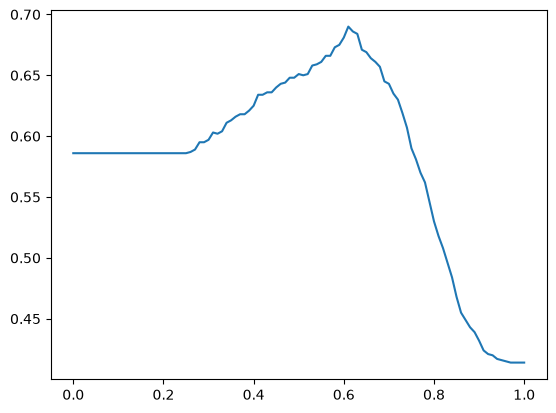

In [24]:
# Question 2

# Plot various accuracy thresholds to see if there is a better threshold than 0.5
thresholds = np.linspace(0, 1, 101)
accuracies = []
for t in thresholds:
    y_pred_temp = (y_pred_probs >= t).astype(int)
    accuracies.append((y_val == y_pred_temp).mean())
plt.plot(thresholds, accuracies)
# From the plot, can see that the best threshold is around 0.6 which yields an accuracy of around 68%. Not much better.
# Can also tell from the plot that around 59% of the people in the validation data convert and around 41% do not.

In [25]:
# Question 2

# Get exact best threshold
thresh = pd.DataFrame()
thresh['thresholds'] = thresholds
thresh['accuracies'] = accuracies
thresh.loc[thresh.accuracies.idxmax()]
# Best threshold is 0.61 which yields an accuracy of 0.69

thresholds    0.61
accuracies    0.69
Name: 61, dtype: float64

In [26]:
# Question 2
# Calculate the AUC of this model on the validation data. Round to 3 decimal places

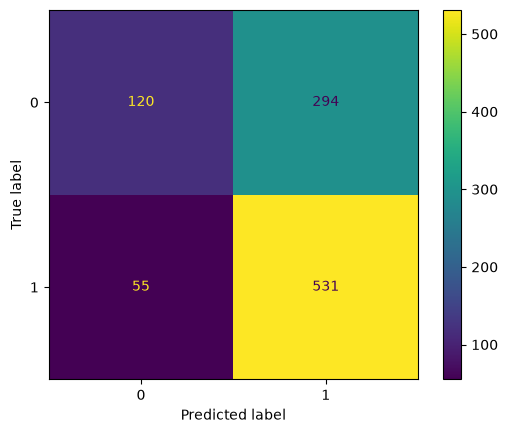

In [27]:
# Question 3
# Now let's compute precision and recall for our model.
# Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
# For each threshold, compute precision and recall. Plot them.
# At which threshold precision and recall curves intersect? 
# Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

# First, let's examine the confusion matrix. 
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
mat = confusion_matrix(y_val, y_pred)
mat_disp = ConfusionMatrixDisplay(mat)
mat_disp.plot()
plt.show()

/tmp/ipykernel_2399/3182168996.py:23: RuntimeWarning: invalid value encountered in scalar divide
  precisions.append(tp / (tp + fp))


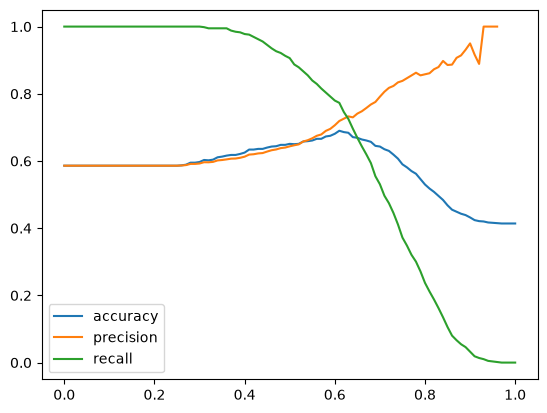

In [28]:
# Question 3
# Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
# For each threshold, compute precision and recall. Plot them.
# At which threshold precision and recall curves intersect? 

# Create a thresholds variable for all the thresholds from 0 to 1 with step 0.01. That's 101 numbers.
thresholds = np.linspace(0, 1, 101)

# Create accuracies, precisions, and recalls to store the respective values at each threshold
accuracies = []
precisions = []
recalls = []

# For each threshold, calculate the new y_pred as y_pred_temp. 
# Use it to calculate accuracy, precision, and recall and append them to their respective list.
for t in thresholds:
    y_pred_temp = (y_pred_probs >= t).astype(int)
    tp = ((y_val == y_pred_temp) & (y_val == 1)).sum()
    tn = ((y_val == y_pred_temp) & (y_val == 0)).sum()
    fp = ((y_val != y_pred_temp) & (y_pred_temp == 1)).sum()
    fn = ((y_val != y_pred_temp) & (y_pred_temp == 0)).sum()
    accuracies.append((y_val == y_pred_temp).mean())
    precisions.append(tp / (tp + fp))
    recalls.append(tp / (tp + fn))
fig, ax = plt.subplots()
ax.plot(thresholds, accuracies, label="accuracy")
ax.plot(thresholds, precisions, label="precision")
ax.plot(thresholds, recalls, label="recall")
ax.legend()
plt.show()